## *In this Notebook We are Doing a Classification Problem in this we Classify Handwritten Digits*

In [59]:
pip show pandas

Name: pandasNote: you may need to restart the kernel to use updated packages.

Version: 2.3.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License
         
         Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
         All rights reserved.
         
         Copyright (c) 2011-2023, Open source contributors.
         
         Redistribution and use in source and binary forms, with or without
         modification, are permitted provided that the following conditions are met:
         
         * Redistributions of source code must retain the above copyright notice, this
           list of conditions and the following disclaimer.
         
         * Redistributions in binary form must reproduce the above copyright notice,
           this list of conditions and

In [60]:
pip install pandas


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [61]:
pip show sklearn

Note: you may need to restart the kernel to use updated packages.


In [62]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


**We are Importing all the necessary libraries which required throghout the project**

In [63]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Flatten

*We are loading the mnist data set which is present in the keras dataset*

In [65]:
(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()

Now We are checking the shapes and descriptions about our dataset which we load

In [66]:
X_train.shape

(60000, 28, 28)

In [67]:
X_test.shape

(10000, 28, 28)

In [68]:
y_train.shape

(60000,)

In [69]:
y_test.shape

(10000,)

In [ ]:
X_test # it give a collections of the numbers (Matrix) for each images 

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

: 

**Now we see the image (original format ) with the help of matplotlib library**

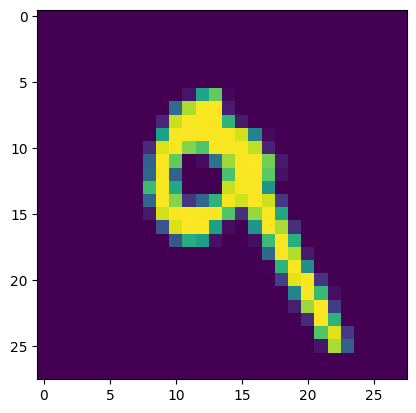

In [70]:
plt.imshow(X_test[7])

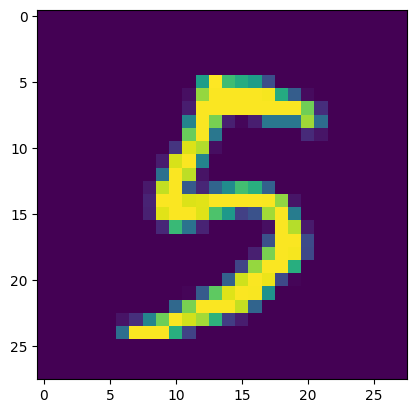

In [71]:
plt.imshow(X_train[6888])

In [72]:
# We can't see the y_train and y_test as image because it is a digit not image
y_train[6888]

5

### Now we scale out input in the range of 0-1 with minMax Scaling the highest value is 255 and the lowest one is 0 

In [73]:
X_train = X_train/255
X_test = X_test/255

In [ ]:
X_train[654]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

: 

## *We are Creating our neural network with the help of tesnorflow*

In [74]:
model = Sequential()


model.add(Flatten(input_shape=(28,28)))
model.add(Dense(128,activation='relu'))
model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(10,activation='softmax'))



In [75]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_2 (Flatten)         (None, 784)               0         
                                                                 
 dense_7 (Dense)             (None, 128)               100480    
                                                                 
 dense_8 (Dense)             (None, 128)               16512     
                                                                 
 dense_9 (Dense)             (None, 64)                8256      
                                                                 
 dense_10 (Dense)            (None, 10)                650       
                                                                 
Total params: 125,898
Trainable params: 125,898
Non-trainable params: 0
_________________________________________________________________


In [76]:
model.compile(loss='sparse_categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [83]:
history = model.fit(X_train,y_train,epochs=20,validation_split=0.2)

Epoch 1/20
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0182 - accuracy: 0.9942 - val_loss: 0.1319 - val_accuracy: 0.9735
Epoch 2/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0123 - accuracy: 0.9961 - val_loss: 0.1203 - val_accuracy: 0.9772
Epoch 3/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0167 - accuracy: 0.9948 - val_loss: 0.1247 - val_accuracy: 0.9762
Epoch 4/20
1500/1500 [==============================] - 7s 4ms/step - loss: 0.0131 - accuracy: 0.9963 - val_loss: 0.1269 - val_accuracy: 0.9772
Epoch 5/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0133 - accuracy: 0.9959 - val_loss: 0.1213 - val_accuracy: 0.9767
Epoch 6/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0107 - accuracy: 0.9965 - val_loss: 0.1293 - val_accuracy: 0.9769
Epoch 7/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0127 - accuracy: 0.9962 - val_loss: 0.1304 - val_accuracy:

In [84]:
y_prob = model.predict(X_test)

313/313 [==============================] - 1s 2ms/step


In [85]:
y_pred = y_prob.argmax(axis = 1)

In [86]:
accuracy_score(y_test,y_pred)

0.977

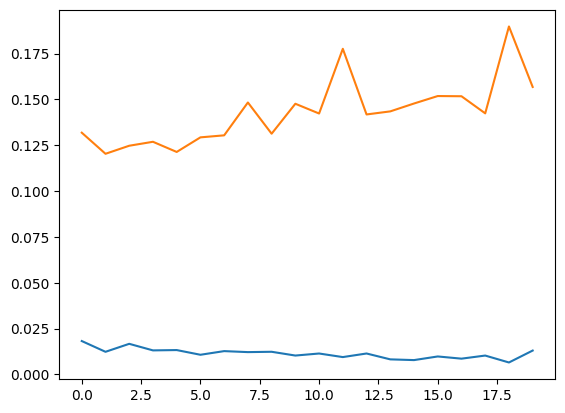

In [87]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

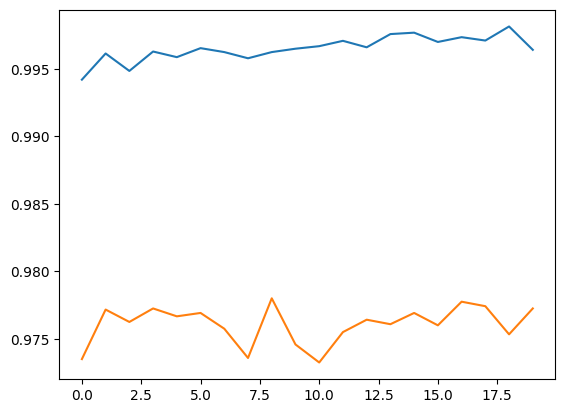

In [88]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

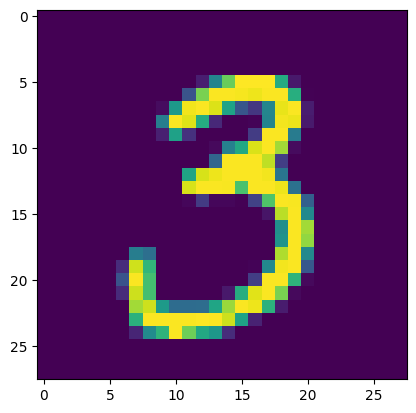

In [89]:
plt.imshow(X_test[90])

In [90]:
model.predict(X_test[90].reshape(1,28,28)).argmax(axis=1)

1/1 [==============================] - 0s 27ms/step


array([3], dtype=int64)

## ***Now we save our trained model for further uses***

In [91]:
model.save("MNIST_Classification_ANN")

INFO:tensorflow:Assets written to: MNIST_Classification_ANN\assets


In [92]:
# with this command we check whether our model saved in our local machine or not 
import os

print("Current directory:", os.getcwd())
print("Model exists:", os.path.exists("MNIST_Classification_ANN"))

Current directory: c:\Users\shiva\Desktop\DL_PROJECTS\MNIST Classification
Model exists: True


### Now we check our model which we saved,is working properly or not 

In [93]:
import tensorflow as tf

loaded_model = tf.keras.models.load_model("MNIST_Classification_ANN")

print("Model loaded successfully!")

loaded_model.summary()

Model loaded successfully!
Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_2 (Flatten)         (None, 784)               0         
                                                                 
 dense_7 (Dense)             (None, 128)               100480    
                                                                 
 dense_8 (Dense)             (None, 128)               16512     
                                                                 
 dense_9 (Dense)             (None, 64)                8256      
                                                                 
 dense_10 (Dense)            (None, 10)                650       
                                                                 
Total params: 125,898
Trainable params: 125,898
Non-trainable params: 0
_________________________________________________________________
